# Python

Nhóm lập trình của lớp có một bảng điểm và muốn thử dự đoán ai cần thêm buổi ôn tập. Vòng lặp, hàm và thuật toán bằng C++ đã là nền tảng; phần việc mới là đọc bảng, gọi thư viện và lưu kết quả để người khác chạy lại được. Khóa học dùng Python cho việc ấy. NumPy, pandas, scikit-learn và PyTorch có giao diện Python, còn nhiều phép tính nặng được thực hiện trong thư viện đã biên dịch.

Kiến thức thuật toán vẫn giữ nguyên giá trị. Điều cần học thêm là cách Python biểu diễn dữ liệu: phép chia số âm khác C++, phép gán list có thể dùng chung đối tượng, và notebook giữ trạng thái giữa các ô. Câu hỏi xuyên suốt bài là: **làm sao viết một chương trình ngắn mà kết quả vẫn đúng khi chạy lại từ đầu?**

> **Sau bài này, có thể**
>
> - Đoán đúng kết quả của phép chia, phép lấy dư và phép so sánh số thực trong Python, kể cả với số âm.
> - Giải thích vì sao sửa một list ở chỗ này lại làm đổi list ở chỗ khác, và chọn đúng cách sao chép.
> - Chọn cấu trúc dữ liệu theo độ phức tạp, đo tốc độ trên cùng một công việc trước khi tối ưu.
> - Đọc, ghi file CSV và đọc được thông báo lỗi để tự sửa code trong notebook.

## Python trong khóa học

Mỗi bước của một vòng lặp Python phải xử lý đối tượng và diễn giải câu lệnh, nên với mảng số lớn, giao phép tính cho NumPy thường nhanh hơn nhiều. Nhanh hơn bao nhiêu thì phải đo trên chính công việc của mình. Thứ tự làm vẫn như khi thi lập trình: viết đúng trước, đo sau; mục “Hàm, vòng lặp và tốc độ” sẽ đo một ví dụ cụ thể.

Một notebook gồm nhiều ô (cell), dùng chung biến trong một tiến trình gọi là kernel. Số ở cạnh ô ghi thứ tự thực thi, không đảm bảo các ô chạy từ trên xuống. Sửa văn bản code cũng chưa làm kết quả cũ đổi theo. Có thể hình dung hai ô: ô trên đặt `n = 3`, ô dưới tính tổng từ 0 đến `n`. Nếu chỉ chạy lại ô trên với `n = 5`, tổng ở ô dưới vẫn là kết quả cũ.



Ta mô phỏng trạng thái đó trong một khối để thấy rõ điều gì cần được tính lại:

In [ ]:
n = 3
total = sum(range(n + 1))
n = 5                       # giống như chạy lại riêng ô đầu
print(n, total)
total = sum(range(n + 1))    # chạy lại bước phụ thuộc
print(n, total)

5 6
5 15


So hai dòng output: cùng `n = 5`, nhưng tổng chỉ thành 15 sau khi câu lệnh tính tổng chạy lại. Khi hoàn tất notebook, khởi động kernel mới rồi chạy tất cả ô từ trên xuống: chỉ kết quả của lượt chạy ấy mới đáng tin.

**Hỏi nhanh.** Vừa mở kernel mới, ta chạy ô `total = sum(range(n + 1))` **trước** ô `n = 3`. Ô ấy cho ra gì?

- A. `total` bằng 0, vì `n` chưa gán thì Python coi là 0
- B. `total` bằng 6, vì Python đọc hết notebook rồi mới chạy
- C. Lỗi `NameError`, vì chưa có tên `n`
- D. `total` dùng lại `n` của lần chạy hôm trước

<details><summary>Đáp án</summary>

C. Lỗi `NameError`, vì chưa có tên `n`

Kernel mới chưa có biến nào. Python cũng không tự cho một tên chưa gán bằng 0, nên báo `NameError`. Đây là lý do nên “Restart and run all” trước khi nộp: notebook nào chỉ chạy được nhờ biến còn sót trong bộ nhớ sẽ lộ lỗi ngay.

</details>

## Chạy notebook trên Colab và Kaggle

Bài nào cũng có một notebook. Nút **Mở trên Colab** và **Mở trên Kaggle** nằm ngay dưới tên bài; bấm vào là notebook mở trong trình duyệt, không cần cài gì trên máy. Chương 0 đến chương 4 chạy tốt trên CPU. Từ chương 5 (mạng nơ-ron ảnh, văn bản) nên bật GPU để huấn luyện vài phút thay vì vài chục phút.

Trên Colab: đăng nhập tài khoản Google, vào *Runtime → Change runtime type*, chọn *T4 GPU*, rồi *Runtime → Run all*. Phiên Colab tự tắt khi để yên lâu; tệp tạo ra trong phiên cũng mất theo, nên tải kết quả về hoặc lưu vào Google Drive.

Trên Kaggle: đăng nhập, mở notebook, nhìn khung *Session options* bên phải. Mục *Accelerator* chọn *GPU T4 x2* hoặc *GPU P100*; mục *Internet* bật *On* nếu notebook cần tải dữ liệu hay cài thư viện. Lần đầu, hai mục này thường bị khóa: Kaggle chỉ mở GPU và Internet cho tài khoản đã xác minh số điện thoại. Vào *kaggle.com/settings*, tìm *Phone verification*, bấm *Verify*, nhập số điện thoại rồi nhập mã SMS. Xác minh một lần là đủ. GPU miễn phí có hạn mức theo tuần (thường khoảng 30 giờ), xem ở mục *Quota* trong khung bên phải; nhớ tắt phiên khi không dùng.

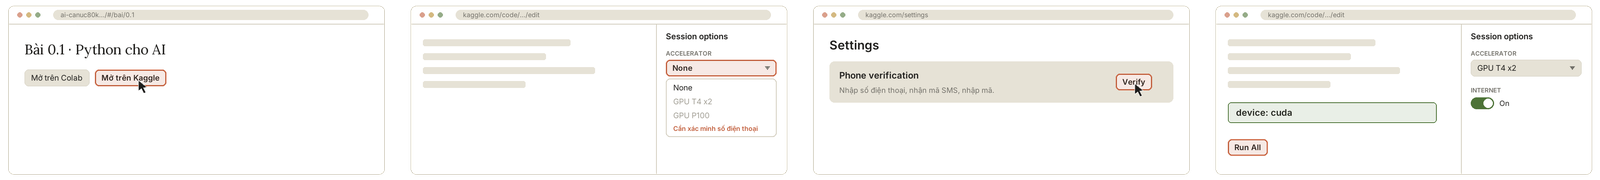

Bật xong, chạy ô kiểm tra này đầu tiên:

In [ ]:
import torch

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('device:', device)

device: cpu


Output trên là của máy không có GPU. Trên Colab hay Kaggle đã bật GPU, dòng in ra là `device: cuda`; nếu vẫn thấy `cpu`, quay lại kiểm mục Accelerator rồi khởi động lại phiên. Khi notebook đã chạy đúng, trên Kaggle bấm *Save Version → Save & Run All (Commit)*: Kaggle chạy lại toàn bộ từ đầu trong một phiên mới và lưu lại output, đúng tinh thần “Restart and run all” ở trên.

**Hỏi nhanh.** Mở notebook trên Kaggle, mục *Accelerator* chỉ chọn được *None*, hai dòng GPU mờ đi. Nguyên nhân thường gặp nhất là gì?

- A. Notebook viết sai, phải sửa code trước thì GPU mới hiện
- B. Tài khoản chưa xác minh số điện thoại
- C. Kaggle chỉ cho dùng GPU vào cuối tuần
- D. Phải cài `torch` bằng `pip` trước khi chọn GPU

<details><summary>Đáp án</summary>

B. Tài khoản chưa xác minh số điện thoại

Kaggle khóa GPU và Internet với tài khoản chưa xác minh số điện thoại. Vào *kaggle.com/settings → Phone verification* làm một lần, quay lại notebook là chọn được GPU. Code trong notebook không ảnh hưởng tới việc mục này có mở hay không.

</details>

## Kiểm tra đầu vào và nhịp cú pháp

Nếu đã dùng Python, hãy tự kiểm năm việc sau trước khi đọc tiếp: `-7 // 2` và `-7 % 2`; tác dụng của `b = a` với list; khác nhau giữa `a.copy()` và `deepcopy(a)`; vì sao tham số mặc định `history=[]` có thể tích lũy từ lần gọi trước; cách ghi CSV rồi đọc lại để kiểm. Nếu làm được cả năm và mười câu cuối bài, có thể đọc lướt phần cú pháp để sang NumPy. Nếu còn vướng một việc, mục tương ứng dưới đây là điểm cần ôn.

Python dùng thụt lề để chia khối, không dùng `{}`. Dấu `:` mở thân hàm, vòng lặp hay điều kiện; các dòng trong cùng khối có cùng độ thụt lề. Quy ước thường dùng là bốn dấu cách. Một ví dụ gắn với bảng điểm:

In [ ]:
def passed_scores(values, threshold=5.0):
    result = []
    for value in values:
        if value >= threshold:
            result.append(value)
    return result

print(passed_scores([4.5, 7.0, 5.0]))
print(list(range(1, 5)))      # đầu được lấy, cuối không được lấy

[7.0, 5.0]
[1, 2, 3, 4]


`return` nằm trong thân hàm nhưng ngoài vòng `for`, nên ta thu đủ kết quả trước khi trả về. `range(1, 5)` có bốn giá trị; quy ước đầu đóng, cuối mở xuất hiện lại trong slicing và NumPy. Đây là hai chi tiết nhỏ đáng kiểm khi chuyển một đoạn C++ sang Python.

## Số và phép toán

`int` của Python có độ chính xác tùy ý: số lớn được cấp thêm bộ nhớ, không quay vòng tại một mốc 32 hay 64 bit. Giới hạn thực tế vẫn là bộ nhớ và thời gian; nhân hai số hàng triệu chữ số không còn là phép toán hằng thời gian.

In [ ]:
print(2 ** 100)
print(2 ** 63 - 1 + 1)               # vượt LLONG_MAX của C++ vẫn đúng

1267650600228229401496703205376
9223372036854775808


Phép chia thì có hai dạng. `/` luôn cho số thực, kể cả khi chia hết. `//` là chia lấy phần nguyên, nhưng làm tròn **xuống** (về phía âm vô cùng), không phải làm tròn về 0 như C++. Phép `%` đi theo `//`, nên với số chia dương thì kết quả luôn không âm:

In [ ]:
print(7 / 2, 6 / 2)
print(7 // 2, -7 // 2)
print(7 % 3, -7 % 3)
print(int(-3.7))                     # int() cắt phần thập phân, về phía 0

3.5 3.0
3 -4
1 2
-3


Trong C++, `-7 / 2` bằng $-3$ và `-7 % 3` bằng $-1$. Trong Python là $-4$ và $2$. Quy tắc của Python giữ đúng đẳng thức `a == (a // b) * b + a % b` và làm `%` tiện hơn khi tính chỉ số vòng tròn: `(i - 1) % n` luôn nằm trong $[0, n)$, không cần cộng thêm $n$.



`float` của Python là số thực nhị phân 64 bit, giống `double` của C++. Phần lớn số thập phân như 0.1 không viết được chính xác bằng hữu hạn chữ số nhị phân:

In [ ]:
import math
print(0.1 + 0.2, 0.1 + 0.2 == 0.3)
print(math.isclose(0.1 + 0.2, 0.3, rel_tol=1e-9, abs_tol=1e-12))
print(round(2.5), round(3.5), round(0.125, 2))

0.30000000000000004 False
True
2 4 0.12




Với kết quả tính toán gần đúng, dùng `math.isclose` hoặc `np.isclose` khi làm với mảng. `rel_tol` cho phép sai lệch theo độ lớn của số, `abs_tol` hữu ích khi so với 0; chọn chúng theo đơn vị và độ chính xác cần kiểm. `==` vẫn phù hợp khi hỏi một giá trị có đúng bằng một mốc được lưu chính xác, nhưng không thay cho kiểm sai số.

Dòng cuối cho thấy `round` chọn số chẵn khi giá trị nằm đúng giữa hai mốc: `round(2.5)` là 2, `round(3.5)` là 4. Số 0.125 biểu diễn chính xác trong nhị phân nên cũng là một trường hợp giữa hai mốc. Với số thập phân khác, giá trị lưu có thể hơi lệch mốc; nếu đề yêu cầu quy tắc làm tròn riêng, phải thực hiện đúng quy tắc ấy.

**Hỏi nhanh.** `print(-7 // 2, -7 % 2)` in ra gì?

- A. `-3 -1`
- B. `-4 1`
- C. `-3 1`
- D. `-3.5 1`

<details><summary>Đáp án</summary>

B. `-4 1`

Trong Python, `//` làm tròn xuống, nên $-3.5$ thành $-4$. Số dư đi theo thương ấy: $-7 - (-4)\cdot 2 = 1$. Ra `-3 -1` là tính theo kiểu C++. Ra `-3 1` là lấy thương kiểu C++ nhưng số dư kiểu Python. Còn `-3.5` là kết quả của phép chia `/`.

</details>

## Biến là cái tên, không phải cái hộp

Trong C++, `vector<int> b = a;` tạo ra một bản sao: hai cái hộp, mỗi hộp chứa dữ liệu riêng. Trong Python, phép gán không bao giờ sao chép dữ liệu. Một biến chỉ là một cái tên dán lên một đối tượng. `b = a` dán thêm tên `b` lên **cùng** đối tượng mà `a` đang chỉ tới.

In [ ]:
a = [1, 2, 3]
b = a
b.append(4)
print(a, b, a is b)

[1, 2, 3, 4] [1, 2, 3, 4] True


Sửa qua `b` thì `a` thấy ngay, vì chỉ có một list. Toán tử `is` hỏi “hai tên có chỉ cùng một đối tượng không”, khác với `==` hỏi “hai đối tượng có bằng nhau không”.

Vậy tại sao với số nguyên lại không thấy hiện tượng này?

In [ ]:
x = 5
y = x
y += 1
print(x, y)

5 6


Vì `int` là bất biến (immutable): không có cách nào sửa đối tượng `5`. Lệnh `y += 1` tạo đối tượng mới `6` rồi dán tên `y` sang đó; `x` vẫn chỉ vào `5`. Các kiểu bất biến gồm `int`, `float`, `str`, `tuple`. Các kiểu sửa được (mutable) gồm `list`, `dict`, `set`, và mảng NumPy. Hiện tượng “sửa chỗ này, đổi chỗ kia” chỉ xảy ra với nhóm thứ hai.



Cách hiểu này giải thích luôn chuyện truyền tham số. Tham số của hàm là tên cục bộ trỏ tới đối tượng được truyền vào. Sửa nội dung list qua tên đó thì người gọi thấy thay đổi; gán lại riêng tên tham số thì không gán lại tên của người gọi.

**Hỏi nhanh.** ```py
def reset(scores):
    scores.append(0)
    scores = []

marks = [7, 8]
reset(marks)
print(marks)
```
Đoạn code trên in ra gì?

- A. `[]`
- B. `[7, 8]`
- C. `[0]`
- D. `[7, 8, 0]`

<details><summary>Đáp án</summary>

D. `[7, 8, 0]`

Khi gọi hàm, `scores` và `marks` là hai cái tên cùng dán lên một list. Vì thế `append(0)` thêm 0 vào đúng list của người gọi. Dòng `scores = []` chỉ bóc nhãn `scores` sang một list rỗng mới, còn `marks` vẫn dán trên list cũ, lúc này là `[7, 8, 0]`.
Phỏng theo: [NOAI 2026 Singapore · Vòng sơ loại · Câu 94](https://aisingapore.org/wp-content/uploads/2026/04/NOAI-2026-Preliminary-Round-Assessment-300-MCQs-Google-Forms.pdf#page=38)

</details>

Muốn một list độc lập thì phải nói rõ:

In [ ]:
a = [1, 2, 3]
c = a.copy()                          # hoặc a[:], list(a)
c.append(4)
print(a, c)

[1, 2, 3] [1, 2, 3, 4]


`copy()` chỉ sao chép một tầng (shallow copy). Với list lồng nhau, các list con vẫn dùng chung. Đây là cái bẫy kinh điển khi tạo bảng hai chiều:

In [ ]:
grid = [[0] * 3] * 3                  # SAI: ba tên cho cùng một hàng
grid[0][0] = 9
print(grid)

grid = [[0] * 3 for _ in range(3)]    # ĐÚNG: mỗi lần lặp tạo một hàng mới
grid[0][0] = 9
print(grid)

[[9, 0, 0], [9, 0, 0], [9, 0, 0]]
[[9, 0, 0], [0, 0, 0], [0, 0, 0]]




Phép `* 3` bên ngoài nhân bản các *tên*, không nhân bản các hàng. Khi cần sao chép sâu mọi tầng, dùng `copy.deepcopy`. Trong thực tế, bảng số nên dùng mảng NumPy (bài 0.2) thay cho list lồng nhau.

**Hỏi nhanh.** Chạy lần lượt `a = [[1, 2], [3, 4]]`, `b = a.copy()`, `b[0].append(9)`. Lúc này `a` là gì?

- A. `[[1, 2], [3, 4]]`
- B. `[[1, 2, 9], [3, 4]]`
- C. `[[1, 2], [3, 4], 9]`
- D. Báo lỗi

<details><summary>Đáp án</summary>

B. `[[1, 2, 9], [3, 4]]`

`copy()` chỉ tạo một list ngoài mới. Hai list con bên trong thì `a` và `b` vẫn dùng chung, nên thêm 9 vào `b[0]` cũng là thêm vào `a[0]`. Muốn chép riêng cả các list con, dùng `copy.deepcopy(a)`.

</details>

## list, tuple, dict, set

Bốn cấu trúc dữ liệu dựng sẵn này thay cho phần lớn STL:

| C++ | Python | Ghi chú |
|---|---|---|
| `vector<T>` | `list` | Chứa được nhiều kiểu; `append` có chi phí amortized $O(1)$ |
| `pair`, `tuple` | `tuple` | Không đổi các vị trí; làm khóa nếu mọi phần tử hashable |
| `unordered_map<K, V>` | `dict` | Giữ thứ tự chèn; tra cứu trung bình $O(1)$ |
| `unordered_set<T>` | `set` | Kiểm tra `in` trung bình $O(1)$ |
| `map`, `set` có thứ tự | không có sẵn | Dùng `sorted()` khi cần, hoặc thư viện ngoài |

Khóa của `dict` và phần tử của `set` phải hashable, tức có giá trị băm không đổi suốt đời đối tượng. Số, chuỗi và tuple chứa toàn phần tử hashable đều dùng được. Tuple chứa một list thì không: bản thân tuple không đổi được, nhưng list bên trong vẫn đổi được, nên giá trị băm không thể ổn định.

Hai cú pháp sẽ gặp ở khắp nơi. Slicing `a[start:stop:step]` lấy một đoạn, với chỉ số âm đếm từ cuối. List comprehension thay cho vòng lặp tạo list:

In [ ]:
a = [5, 3, 8, 1, 9, 2]
print(a[1:4], a[-1], a[-2:], a[::-1])
print([x * x for x in a if x % 2 == 1])

scores = {"An": 8.5, "Bình": 6.0}
scores["Chi"] = 9.0
print(scores.get("Dũng", 0.0), len(scores), "An" in scores)

[3, 8, 1] 2 [9, 2] [2, 9, 1, 8, 3, 5]
[25, 9, 1, 81]
0.0 3 True


`dict.get(key, mặc_định)` tránh lỗi khi khóa chưa có. Để đếm tần suất, `collections.Counter` làm sẵn việc mà trong C++ ta thường tự viết bằng `map<string, int>`:

In [ ]:
from collections import Counter
words = "mèo chó mèo gà mèo chó".split()
print(Counter(words).most_common(2))
print(sorted(scores.items(), key=lambda kv: -kv[1]))

[('mèo', 3), ('chó', 2)]
[('Chi', 9.0), ('An', 8.5), ('Bình', 6.0)]


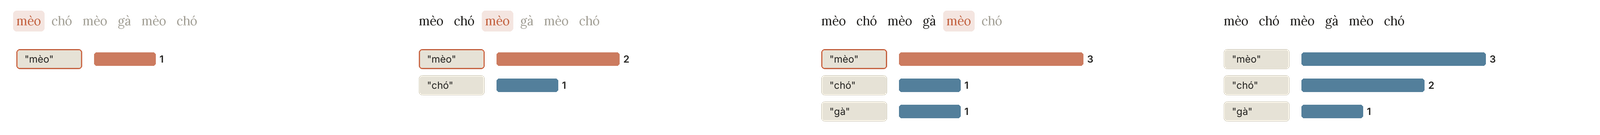

`sorted` nhận tham số `key` thay cho hàm so sánh của C++. Ở đây sắp xếp các cặp (tên, điểm) theo điểm giảm dần.

Độ phức tạp vẫn quan trọng như trong lập trình thi đấu. Kiểm tra `x in L` với list có thể phải duyệt cả list, $O(n)$; với set, tra cứu có chi phí trung bình $O(1)$ khi việc băm hoạt động tốt. Đổi sang set một lần tốn thời gian và bộ nhớ, nhưng có ích khi phải hỏi nhiều lần:

In [ ]:
L = list(range(10**5))
S = set(L)
queries = range(-500, 500)

r1 = [query in L for query in queries]
r2 = [query in S for query in queries]
print(r1 == r2, sum(r2))

True 500


Hai cách cho cùng kết quả, và đúng 500 truy vấn không âm xuất hiện trong tập. Ta chưa cần một con số thời gian để thấy khác biệt về quy mô: mỗi truy vấn âm buộc list đi đến cuối, còn set dùng bảng băm. Khi dữ liệu ít hoặc chỉ hỏi một lần, chi phí dựng set cũng cần được tính vào quyết định.



**Hỏi nhanh.** Có 50 000 mã học sinh đã nộp bài. Cần kiểm 10 000 mã khác xem từng mã đã nộp hay chưa. Nên làm thế nào?

- A. Đổi danh sách 50 000 mã thành `set` rồi dùng `in`
- B. Cứ để list và dùng `in`, 50 000 phần tử chưa nhiều
- C. Sắp xếp list trước để `in` chạy nhanh hơn
- D. Viết hai vòng `for` lồng nhau cho dễ kiểm

<details><summary>Đáp án</summary>

A. Đổi danh sách 50 000 mã thành `set` rồi dùng `in`

Với list, mỗi lần `in` phải dò từ đầu đến cuối, tổng cộng cỡ $10^4 \times 5\cdot 10^4 = 5\cdot 10^8$ phép so sánh, quá chậm với Python. Set dùng bảng băm nên mỗi lần tra trung bình chỉ mất $O(1)$. Sắp xếp list không giúp gì, vì `in` vẫn dò lần lượt từng phần tử.

</details>

## Hàm, vòng lặp và tốc độ

Vòng `for` của Python duyệt thẳng các phần tử, không cần chỉ số. Khi cần cả chỉ số thì dùng `enumerate`, khi duyệt song song hai dãy thì dùng `zip`:

In [ ]:
names = ["An", "Bình", "Chi"]
marks = [8.5, 6.0, 9.0]
for i, (name, mark) in enumerate(zip(names, marks), start=1):
    print(f"{i}. {name}: {mark}")

1. An: 8.5
2. Bình: 6.0
3. Chi: 9.0


Hàm có tham số mặc định, gọi được bằng tên tham số, và trả về nhiều giá trị (thật ra là một tuple):

In [ ]:
def stats(xs, ddof=0):
    n = len(xs)
    if not 0 <= ddof < n:
        raise ValueError("cần 0 <= ddof < số phần tử")
    mean = sum(xs) / n
    var = sum((x - mean) ** 2 for x in xs) / (n - ddof)
    return mean, var

m, v = stats(marks)
print(round(m, 3), round(v, 3), round(stats(marks, ddof=1)[1], 3))

7.833 1.722 2.583


Trung bình là 7.833; phương sai chia cho $n$ là 1.722. Nếu chia cho $n-1$, kết quả là 2.583. `ddof` cho biết bớt bao nhiêu ở mẫu số; lựa chọn phụ thuộc câu hỏi thống kê. Điều kiện đầu hàm tránh chia cho 0 khi danh sách rỗng hoặc có quá ít phần tử.

Có một cái bẫy với tham số mặc định: giá trị mặc định được tạo **một lần** khi định nghĩa hàm, không phải mỗi lần gọi. Nếu nó là một list, mọi lần gọi dùng chung list đó:

In [ ]:
def add_score(x, history=[]):          # SAI
    history.append(x)
    return history

print(add_score(1), add_score(2))

def add_score(x, history=None):        # ĐÚNG
    if history is None:
        history = []
    history.append(x)
    return history

print(add_score(1), add_score(2))

[1, 2] [1, 2]
[1] [2]


Ở bản sai, hai lần gọi trả về **cùng một** list, nên khi `print` chạy thì cả hai đều đã chứa `[1, 2]`. Lần gọi thứ hai không bắt đầu từ list rỗng như ta tưởng. Bản đúng dùng `None` làm giá trị mặc định và tạo list mới bên trong hàm.



**Hỏi nhanh.** Hàm `add_score(score, history=[])` có lỗi: gọi lần sau vẫn thấy điểm của các lần trước trong `history`. Sửa thế nào để mỗi lần gọi mà không truyền `history` thì bắt đầu từ danh sách rỗng?

- A. Giữ `history=[]`, gọi `history.clear()` ở cuối hàm
- B. Giữ `history=[]`, vì mỗi lần gọi Python tạo lại list
- C. Đặt `history=None`, rồi tạo list mới trong hàm
- D. Dùng một list toàn cục, gán lại `[]` trước mỗi lần gọi

<details><summary>Đáp án</summary>

C. Đặt `history=None`, rồi tạo list mới trong hàm

Giá trị mặc định chỉ được tạo một lần, lúc Python đọc dòng `def`, nên mọi lần gọi dùng chung một list. Đặt mặc định là `None` rồi viết `if history is None: history = []` trong hàm thì mỗi lần gọi có một list riêng. Gọi `clear()` ở cuối hàm sẽ xóa luôn list vừa trả về. List toàn cục vẫn chạy, nhưng mọi chỗ gọi dính chung một trạng thái.

</details>

Giờ đến tốc độ. So ba cách tính cùng tổng $0 + 1 + \dots + (n - 1)$ với $n = 500\,000$. Công thức $n(n-1)/2$ cho một đáp án độc lập, giống code trâu dùng để kiểm nghiệm trong lập trình thi đấu:

In [ ]:
import numpy as np

def loop_sum(n):
    s = 0
    for i in range(n):
        s += i
    return s

n = 500_000
expected = n * (n - 1) // 2
print(loop_sum(n), expected)
print(loop_sum(n) == sum(range(n)) == int(np.arange(n, dtype=np.int64).sum()))

124999750000 124999750000
True


Đáp án khớp rồi mới đo. `timeit.repeat` chạy mỗi cách năm lần, mỗi lần gộp ba lượt (`number=3`) rồi chia cho 3; lấy lần nhanh nhất để bớt nhiễu do các tiến trình khác trên máy.

In [ ]:
from timeit import repeat

jobs = [
    ("for", lambda: loop_sum(n)),
    ("sum", lambda: sum(range(n))),
    ("numpy", lambda: int(np.arange(n, dtype=np.int64).sum())),
]
timings = {}
for label, job in jobs:
    assert job() == expected
    timings[label] = min(repeat(job, repeat=5, number=3)) / 3
print("nhanh -> chậm:", sorted(timings, key=timings.get))

nhanh -> chậm: ['numpy', 'sum', 'for']




NumPy nhanh nhất dù phải tạo mảng, rồi đến `sum` dựng sẵn, vòng `for` tự viết chậm nhất; số giây cụ thể của máy đang dùng nằm trong biến `timings`, và hình trên vẽ từ một lần đo như vậy. Với riêng bài này, công thức $n(n-1)/2$ còn thắng cả ba vì bỏ hẳn vòng lặp: thuật toán tốt vẫn đứng trước thư viện nhanh. Bài 0.2 sẽ giao các phép toán mảng cho NumPy.

**Hỏi nhanh.** Hai cách cài đều tính đúng cùng một tổng. Cách A chạy 8 ms nhưng phải mất thêm 5 ms chuẩn bị dữ liệu. Cách B chạy 11 ms và dùng luôn dữ liệu có sẵn. Nếu chỉ chạy một lần, cách nào nhanh hơn?

- A. B nhanh hơn: 11 ms so với 13 ms
- B. Như nhau, vì cùng độ phức tạp $O(n)$
- C. Chưa so được, vì mỗi lần đo một khác
- D. A nhanh hơn: 8 ms so với 11 ms

<details><summary>Đáp án</summary>

A. B nhanh hơn: 11 ms so với 13 ms

Phải cộng cả thời gian chuẩn bị: A tốn $5 + 8 = 13$ ms, B tốn 11 ms. Cùng độ phức tạp chưa chắc chạy nhanh như nhau. Thời gian đo có dao động, nhưng khi đã đo cẩn thận thì dao động không xóa được chênh lệch 2 ms này. Nếu dữ liệu của A chuẩn bị một lần rồi dùng cho nhiều lần chạy thì lại là chuyện khác, phải đo riêng.

</details>

## Chuỗi và file

Chuỗi `str` là bất biến và chứa Unicode, nên tiếng Việt có dấu không cần xử lý gì đặc biệt. Cách định dạng nên dùng là f-string: biểu thức trong `{}`, định dạng sau dấu `:`.

In [ ]:
name, acc = "logistic", 0.85432
print(f"{name:>10} | accuracy = {acc:.3f} | {acc:.1%}")
line = "  12, 7.5 ,An \n"
print(line.strip().split(","), [s.strip() for s in line.split(",")])
print(" - ".join(["a", "b", "c"]))

  logistic | accuracy = 0.854 | 85.4%
['12', ' 7.5 ', 'An'] ['12', '7.5', 'An']
a - b - c


`strip` bỏ khoảng trắng hai đầu, `split` cắt theo dấu phân cách, `join` ghép ngược lại. Đọc dữ liệu thô từ file thường chỉ cần bộ ba này.

Đọc và ghi file dùng `open` trong khối `with`, khối này đóng file kể cả khi có lỗi. Ghi rõ `encoding="utf-8"` để không phụ thuộc encoding mặc định của máy. Module `csv` hiểu dấu phẩy nằm trong ô được đặt ngoặc kép; `split(",")` đơn thuần không đủ cho mọi CSV.

Ví dụ sau tạo thư mục tạm **bên trong thư mục làm việc**, ghi file rồi đọc lại và tự dọn thư mục tạm khi kết thúc. Khi làm đề thật, dùng đúng đường dẫn bài yêu cầu và giữ file cần nộp:

In [ ]:
import csv
from pathlib import Path
from tempfile import TemporaryDirectory

preds = {1: 0.91, 2: 0.15, 3: 0.67}
with TemporaryDirectory(dir=".") as directory:
    path = Path(directory) / "submission.csv"
    with path.open("w", newline="", encoding="utf-8") as file:
        writer = csv.writer(file)
        writer.writerow(["id", "prediction"])
        for student_id, prediction in preds.items():
            writer.writerow([student_id, prediction])
    with path.open(encoding="utf-8", newline="") as file:
        rows = list(csv.reader(file))
print(rows)
print(type(rows[1][1]), float(rows[1][1]) + 1)

[['id', 'prediction'], ['1', '0.91'], ['2', '0.15'], ['3', '0.67']]
<class 'str'> 1.9100000000000001


Mọi thứ đọc từ CSV đều là chuỗi, kể cả `"0.91"`. Phải đổi sang số trước khi tính hay sắp xếp: sắp xếp chuỗi thì `"10"` đứng trước `"9"`. Bài 0.3 sẽ dùng pandas để đọc CSV, tự đoán kiểu cho từng cột. Module `csv` vẫn đáng biết khi file quá lạ để pandas đoán đúng.

**Hỏi nhanh.** Đọc cột điểm bằng module `csv`, ta được `["9", "10", "2"]`. `sorted` trả về gì?

- A. `['2', '9', '10']`
- B. `['10', '2', '9']`
- C. `['9', '10', '2']`
- D. `TypeError`, vì không sắp xếp được chuỗi

<details><summary>Đáp án</summary>

B. `['10', '2', '9']`

Các phần tử vẫn là chuỗi, mà chuỗi được so từng ký tự từ trái sang. Vì `'1' < '2' < '9'` nên `"10"` đứng đầu, dù 10 là số lớn nhất. Muốn sắp theo giá trị số thì đổi kiểu trước, hoặc viết `sorted(values, key=float)`.

</details>

## Đọc lỗi

Khi code lỗi, Python in một traceback: danh sách các lời gọi hàm dẫn đến chỗ lỗi, dòng cuối cùng là loại lỗi và thông báo. Đọc từ **dưới lên**: dòng cuối cho biết chuyện gì xảy ra, các dòng ngay trên cho biết ở đâu.



Bốn loại lỗi gặp nhiều nhất trong khóa học:

In [ ]:
tests = [lambda: "Điểm: " + 9, lambda: scores["Dũng"], lambda: marks[3], lambda: int("7.5")]
for f in tests:
    try:
        f()
    except Exception as e:
        print(type(e).__name__ + ":", e)

TypeError: can only concatenate str (not "int") to str
KeyError: 'Dũng'
IndexError: list index out of range
ValueError: invalid literal for int() with base 10: '7.5'


`TypeError` là dùng sai kiểu: cộng chuỗi với số phải viết `f"Điểm: {9}"` hoặc `"Điểm: " + str(9)`. `KeyError` là tra khóa không có trong dict. `IndexError` là chỉ số vượt độ dài. `ValueError` là giá trị không thích hợp, như `int("7.5")`. Nếu ô là điểm có phần thập phân thì dùng `float("7.5")`; chỉ bọc thêm `int(...)` khi bài yêu cầu cắt phần lẻ. Bắt ngoại lệ trong ví dụ để cả notebook tiếp tục được; lúc debug thường nên để traceback đầy đủ chỉ ra dòng hỏng.

Khi kết quả sai mà không có lỗi, cách nhanh nhất là in ra kiểu, độ dài, vài phần tử đầu ở từng bước, hoặc đặt `assert` cho giả định cần kiểm. `assert len(preds) == 3, len(preds)` dừng chương trình ngay khi giả định sai và in ra giá trị thật. Các bài sau dùng cách này rất nhiều với shape của mảng.

**Hỏi nhanh.** Quen đếm từ 1 như nhiều bài C++, một bạn viết `for i in range(1, len(marks) + 1): print(marks[i])`, với `marks` có 3 phần tử. Vòng lặp chạy ra sao?

- A. In đủ ba phần tử, như vòng 1 đến n bên C++
- B. Báo `IndexError` ngay ở vòng đầu
- C. In `marks[1]`, `marks[2]` rồi dừng bình thường
- D. In `marks[1]`, `marks[2]`, rồi `IndexError` ở `i = 3`

<details><summary>Đáp án</summary>

D. In `marks[1]`, `marks[2]`, rồi `IndexError` ở `i = 3`

List 3 phần tử có chỉ số 0, 1, 2. Vòng lặp bỏ qua phần tử đầu, in `marks[1]`, `marks[2]`, rồi đến `i = 3` thì vượt ra ngoài list. Duyệt thẳng phần tử bằng `for mark in marks`, hoặc dùng `enumerate`, thì không mắc lỗi này.
Phỏng theo: [NOAI 2026 Singapore · Vòng sơ loại · Câu 137](https://aisingapore.org/wp-content/uploads/2026/04/NOAI-2026-Preliminary-Round-Assessment-300-MCQs-Google-Forms.pdf#page=52)

</details>

## Class: gói dữ liệu cùng cách dùng nó

Từ chương 3, gần như mọi model đều được viết dưới dạng `class Net(nn.Module)`, và dữ liệu đi qua `Dataset` với hai hàm `__len__`, `__getitem__`. Cú pháp class của Python khác C++ ở vài chỗ, nên ta làm quen ngay từ bây giờ bằng chính bảng điểm của lớp.

Một class gom dữ liệu và các hàm làm việc với dữ liệu ấy. Hàm `__init__` chạy khi tạo đối tượng mới. Tham số đầu tiên của mọi phương thức là `self`, chính là đối tượng đang được gọi; Python tự truyền nó, giống con trỏ `this` của C++ nhưng phải viết ra. Thuộc tính gán qua `self.tên` thì sống cùng đối tượng.

In [ ]:
class ScoreBook:
    def __init__(self, names, marks):
        assert len(names) == len(marks), "mỗi tên một điểm"
        self.names = list(names)
        self.marks = list(marks)

    def __len__(self):
        return len(self.marks)

    def __getitem__(self, i):
        return self.names[i], self.marks[i]

    def mean(self):
        return sum(self.marks) / len(self)

book = ScoreBook(["An", "Bình", "Chi"], [8.5, 6.0, 9.0])
print(len(book), book[1], round(book.mean(), 3))
for name, mark in book:
    print(name, mark)

3 ('Bình', 6.0) 7.833
An 8.5
Bình 6.0
Chi 9.0


Các hàm có hai dấu gạch dưới ở hai đầu là “hàm đặc biệt”: Python gọi chúng khi gặp cú pháp quen thuộc. `len(book)` gọi `book.__len__()`, `book[1]` gọi `book.__getitem__(1)`. Vòng `for` cũng chạy được, vì Python gọi `__getitem__` với 0, 1, 2… cho tới khi gặp `IndexError`. Đó đúng là hợp đồng của `torch.utils.data.Dataset` ở bài 3.4: viết đủ `__len__` và `__getitem__` là `DataLoader` tự chia batch được.

Class con kế thừa class cha bằng cách ghi tên cha trong ngoặc. `super().__init__(...)` gọi phần khởi tạo của cha để các thuộc tính của cha cũng được tạo. Hàm `__call__` cho phép gọi đối tượng như gọi hàm:

In [ ]:
class Scaler:
    def __init__(self, factor):
        self.factor = factor

    def __call__(self, values):
        return self.forward(values)

    def forward(self, values):
        return [v * self.factor for v in values]

class ShiftScaler(Scaler):
    def __init__(self, factor, shift):
        super().__init__(factor)
        self.shift = shift

    def forward(self, values):
        return [v + self.shift for v in super().forward(values)]

f = ShiftScaler(2, 1)
print(f([1, 2, 3]), f.factor, isinstance(f, Scaler))

[3, 5, 7] 2 True


`f([1, 2, 3])` gọi `__call__` của `Scaler`, hàm này gọi `self.forward`, và vì `f` là `ShiftScaler` nên bản `forward` của class con chạy: nhân 2 bằng `forward` của cha, rồi cộng 1. PyTorch làm đúng như vậy: `model(x)` gọi `nn.Module.__call__`, rồi `__call__` gọi `forward` mà ta tự viết. Vì thế trong PyTorch ta viết `forward` nhưng gọi `model(x)`, không gọi `model.forward(x)`.



**Hỏi nhanh.** Trong `ShiftScaler.__init__`, một bạn xóa dòng `super().__init__(factor)` vì thấy đã có `self.shift = shift`. Gọi `ShiftScaler(2, 1)([1, 2, 3])` thì sao?

- A. Vẫn ra `[3, 5, 7]`, vì Python tự gọi `__init__` của class cha
- B. Ra `[2, 3, 4]`, vì thiếu `factor` thì Python coi là 1
- C. Báo `AttributeError`, vì đối tượng chưa có thuộc tính `factor`
- D. Báo lỗi ngay ở dòng tạo đối tượng, trước khi gọi

<details><summary>Đáp án</summary>

C. Báo `AttributeError`, vì đối tượng chưa có thuộc tính `factor`

Python chỉ chạy đúng một hàm `__init__`, là hàm của class con. Phần gán `self.factor` nằm trong `__init__` của cha, không còn ai gọi tới, nên khi `forward` của cha đọc `self.factor` thì báo `AttributeError`. Tạo đối tượng thì vẫn thành công, lỗi chỉ lộ ra lúc dùng. Python cũng không tự đặt giá trị mặc định cho thuộc tính chưa gán. Với PyTorch, quên `super().__init__()` trong một `nn.Module` còn báo lỗi sớm hơn, ngay khi gán lớp con đầu tiên.

</details>

## Ví dụ tính tay

Đoán kết quả trước khi chạy, rồi mới chạy để kiểm tra. Đây là cách nhanh nhất để biết mình đã thật sự hiểu mô hình “tên và đối tượng” hay chưa.

1. `a = [1, 2]; b = a; a = a + [3]; print(b)`. Kết quả là `[1, 2]`. `a + [3]` tạo list **mới** rồi dán tên `a` sang đó; `b` vẫn chỉ vào list cũ. So với `a += [3]`, phép này sửa thẳng list cũ, nên `b` sẽ thấy `[1, 2, 3]`.
2. `print(10 // -3, 10 % -3)`. $10 / (-3) = -3.33$, làm tròn xuống được $-4$; $10 - (-4)(-3) = -2$. Kết quả `-4 -2`: với số chia âm, `%` cho kết quả không dương.
3. `s = "abc"; t = s; t += "d"; print(s)`. Kết quả `abc`, vì chuỗi bất biến: `t += "d"` tạo chuỗi mới.
4. `d = {}; d[(1, 2)] = "x"; d[[1, 2]] = "y"`. Dòng cuối báo `TypeError: unhashable type: 'list'`. Tuple hai số nguyên hashable; list thì không. Tuple chứa list cũng không làm khóa được.

## Bẫy cài đặt

**Đặt tên biến trùng hàm dựng sẵn.** Trong notebook, viết `sum = 0` ở một ô nào đó thì mọi lời gọi `sum(...)` về sau đều hỏng cho đến khi khởi động lại:

In [ ]:
sum = 0
try:
    sum([1, 2, 3])
except TypeError as e:
    print("TypeError:", e)
del sum                               # gỡ cái tên, sum dựng sẵn quay lại
print(sum([1, 2, 3]))

TypeError: 'int' object is not callable
6


Những tên hay bị đè: `sum`, `max`, `min`, `list`, `dict`, `id`, `input`, `type`, `len`. Đặt `total`, `best`, `ids` thay vào.

**Sửa list trong khi đang duyệt nó.** `for x in a: if x < 0: a.remove(x)` sẽ bỏ sót phần tử, vì xóa làm các phần tử sau dồn lên. Tạo list mới: `a = [x for x in a if x >= 0]`.

**Chạy ô lệch thứ tự.** Biến cũ còn sống trong bộ nhớ làm notebook “chạy được” trên máy đang dùng nhưng hỏng khi chạy lại từ đầu. *Restart and run all* trước khi nộp.

**`is` thay cho `==`.** `is` so danh tính đối tượng, `==` so giá trị. Trong code thông thường, dùng `is None` để kiểm thiếu tham số; không dùng `is` để so hai số hay hai chuỗi có cùng nội dung.

## Khi đi thi

- **Restart and run all** trước mỗi lần nộp. Một notebook không chạy lại được từ đầu là một bài nộp không tái lập được.
- **Ghi rõ seed** cho các nguồn ngẫu nhiên đang dùng. Seed giúp tái tạo lựa chọn ngẫu nhiên trong cùng môi trường; không đảm bảo mọi phép tính GPU giống từng bit.
- **Đo trước khi tối ưu.** Dữ liệu số lớn thường phù hợp NumPy; các vòng điều khiển theo file, epoch hay tham số vẫn cần Python.
- **Dùng `pathlib` theo đường dẫn đề cung cấp**, kiểm tra thư mục và tên file trước khi đọc. Quy định thư viện, Internet và runtime phải lấy từ môi trường hoặc thông báo của bài thi.
- **Ghi file với `encoding="utf-8"`** và đọc lại file nộp để kiểm tra số dòng, tên cột trước khi nộp.

## Tóm tắt

- Python kết nối các bước xử lý; benchmark trên cùng công việc cho biết phần nào đáng tối ưu. Không có tốc độ cố định cho mọi vòng lặp.
- `int` có độ chính xác tùy ý. `//` làm tròn xuống, `%` đi theo nó, khác C++ với số âm. Kiểm kết quả số thực gần đúng bằng tolerance thích hợp.
- Biến là tên dán lên đối tượng; phép gán không sao chép. Kiểu sửa được (list, dict, set, mảng NumPy) có thể bị sửa qua tên khác. Sao chép bằng `copy()`, sâu hơn thì `deepcopy`.
- list, tuple, dict, set thay cho STL; chọn theo độ phức tạp, đặc biệt là `in` trên set thay cho list.
- Ghi file với `encoding="utf-8"`; dữ liệu đọc từ CSV là chuỗi. Đọc traceback từ dưới lên.

## Kiểm tra cuối bài

Mười câu dưới đây bao quát cả bài. Làm hết rồi xem điểm; câu nào sai thì đọc lại mục tương ứng.

**Câu 1.** Sau `a = [1, 2]`, `b = [1, 2]`, `c = a`, lệnh `print(a == b, a is b, a is c)` in ra gì?

- A. `True True True`
- B. `True False True`
- C. `False False True`
- D. `True False False`

<details><summary>Đáp án</summary>

B. `True False True`

`==` so nội dung, nên `a == b` là `True`. `is` hỏi hai tên có dán trên cùng một đối tượng không. `a` và `b` là hai list tạo ở hai lệnh khác nhau, nên `a is b` là `False`. Còn `c = a` chỉ dán thêm tên `c` lên list của `a`, nên `a is c` là `True`.
Phỏng theo: [NOAI 2026 Singapore · Vòng sơ loại · Câu 95](https://aisingapore.org/wp-content/uploads/2026/04/NOAI-2026-Preliminary-Round-Assessment-300-MCQs-Google-Forms.pdf#page=38)

</details>
**Câu 2.** Có `n` phần tử xếp thành vòng tròn, đánh số từ 0 đến `n - 1`. Biểu thức nào cho số thứ tự của phần tử đứng ngay trước `i`, kể cả khi `i = 0`?

- A. `(i + 1) % n`
- B. `abs(i - 1) % n`
- C. `(i - 1) // n`
- D. `(i - 1) % n`

<details><summary>Đáp án</summary>

D. `(i - 1) % n`

Khi số chia dương, `%` của Python luôn cho kết quả từ 0 đến `n - 1`, kể cả với số âm. Tại `i = 0`, `(0 - 1) % n` bằng `n - 1`, đúng phần tử cuối vòng. `(i + 1) % n` là phần tử đứng sau. `abs(i - 1) % n` cho 1 khi `i = 0`. `(i - 1) // n` là thương chứ không phải số thứ tự.

</details>
**Câu 3.** `0.1 * 3 == 0.3` cho kết quả gì? Muốn so hai số thực như vậy thì nên viết thế nào?

- A. `False`; dùng `math.isclose(0.1 * 3, 0.3)`
- B. `True`; dùng `==` là được
- C. Báo lỗi, vì không so được số thực
- D. `False`; đổi cả hai sang `int` rồi so

<details><summary>Đáp án</summary>

A. `False`; dùng `math.isclose(0.1 * 3, 0.3)`

Máy lưu số thực ở hệ nhị phân, và 0.1 không viết chính xác được trong hệ này, nên `0.1 * 3` ra `0.30000000000000004`. So hai số thực thì so gần đúng bằng `math.isclose`. Đổi sang `int` thì mất phần thập phân, so như thế không còn ý nghĩa.

</details>
**Câu 4.** Sau bốn lệnh `a = [[1, 2], [3, 4]]`, `b = a.copy()`, `b[0] = [9, 9]`, `b[1].append(5)`, `a` là gì?

- A. `[[1,2],[3,4]]`
- B. `[[1,2],[3,4,5]]`
- C. `[[9,9],[3,4]]`
- D. `[[9,9],[3,4,5]]`

<details><summary>Đáp án</summary>

B. `[[1,2],[3,4,5]]`

`b[0] = [9, 9]` chỉ thay ô đầu trong list ngoài của riêng `b`, nên `a[0]` giữ nguyên. Còn list con thứ hai thì `a` và `b` vẫn dùng chung, nên thêm 5 vào `b[1]` cũng làm `a[1]` đổi theo.

</details>
**Câu 5.** Chạy `grid = [[0] * 3] * 2` rồi `grid[1][2] = 7`. Lúc này `grid` là gì, và phải sửa dòng tạo `grid` thế nào để hai hàng không dính nhau?

- A. `[[0,0,0],[0,0,7]]`; thêm `grid = grid.copy()` sau khi tạo
- B. `[[0,0,0],[0,0,7]]`; không cần sửa, hai hàng đã riêng
- C. `[[0,0,7],[0,0,7]]`; dùng `grid=[[0]*3 for _ in range(2)]`
- D. `[[0,0,7],[0,0,7]]`; dùng `grid=[([0]*3).copy()]*2`

<details><summary>Đáp án</summary>

C. `[[0,0,7],[0,0,7]]`; dùng `grid=[[0]*3 for _ in range(2)]`

`* 2` không tạo hai hàng, mà đặt cùng một hàng vào hai chỗ, nên sửa hàng 1 thì hàng 0 cũng đổi. List comprehension chạy `[0] * 3` một lần cho mỗi hàng, nên mỗi hàng là một list riêng. `grid.copy()` chỉ chép list ngoài. Còn copy một hàng rồi mới nhân 2 thì hai chỗ vẫn trỏ vào cùng một bản copy.

</details>
**Câu 6.** Hàm `def f(x, acc=[]): acc.append(x); return len(acc)` được gọi ba lần liền: `f(1)`, `f(2)`, `f(3)`. Lần thứ ba trả về bao nhiêu?

- A. 1
- B. 2
- C. 3
- D. Báo lỗi

<details><summary>Đáp án</summary>

C. 3

List mặc định chỉ được tạo một lần, lúc định nghĩa hàm, rồi dùng chung cho mọi lần gọi. Sau ba lần gọi, list ấy có ba phần tử. Cách sửa là đặt `acc=None` rồi tạo list mới trong thân hàm.

</details>
**Câu 7.** Cần đánh số các token khác nhau trong `tokens = ["mèo", "chó", "mèo"]` thành 0, 1, 2,… Yêu cầu: chạy lại lần nào cũng ra đúng một bảng số, kể cả khi đổi thứ tự token trong dữ liệu. Viết thế nào?

- A. `vocab = {token: i for i, token in enumerate(sorted(set(tokens)))}`
- B. `vocab = {token: i for i, token in enumerate(list(set(tokens)))}`
- C. `vocab = {token: i for i, token in enumerate(sorted(tokens))}`
- D. `vocab = {token: tokens.index(token) for token in tokens}`

<details><summary>Đáp án</summary>

A. `vocab = {token: i for i, token in enumerate(sorted(set(tokens)))}`

`set` bỏ trùng nhưng không giữ thứ tự cố định: với chuỗi, mỗi lần chạy Python có thể duyệt theo một thứ tự khác. Sắp xếp rồi mới đánh số thì lần nào cũng ra cùng một bảng. `sorted(tokens)` không bỏ trùng, nên “mèo” bị gán đè thành số 2 và các số không còn liền nhau. `tokens.index` đánh số theo vị trí xuất hiện đầu tiên, nên đổi thứ tự token là bảng số đổi theo.
Phỏng theo: [USA-NA-AIO 2026 · Vòng 1 · Part 5.1–5.2](https://www.usaaio.org/attachments/past-problems/2026/usaaio-2026-round-1-problems.pdf#page=11)

</details>
**Câu 8.** Quen C++, một bạn muốn cộng từng phần tử của hai dãy nên viết `[1, 2] + [3, 4]`. Python cho kết quả gì?

- A. `[4, 6]`
- B. `[[1, 2], [3, 4]]`
- C. Báo lỗi
- D. `[1, 2, 3, 4]`

<details><summary>Đáp án</summary>

D. `[1, 2, 3, 4]`

Với list, `+` là phép nối, giống cộng hai chuỗi. Muốn cộng từng cặp phần tử thì dùng mảng NumPy ở bài 0.2: `np.array([1, 2]) + np.array([3, 4])` mới ra `[4, 6]`.
Đề thi: [NOAI 2026 Singapore · Vòng sơ loại · Câu 91](https://aisingapore.org/wp-content/uploads/2026/04/NOAI-2026-Preliminary-Round-Assessment-300-MCQs-Google-Forms.pdf#page=37)

</details>
**Câu 9.** Đọc file CSV bằng module `csv`, ô `row[1]` hiện là `8.5`. Biểu thức `row[1] + 1` cho kết quả gì?

- A. `9.5`
- B. `"8.51"`
- C. `TypeError`
- D. `ValueError`

<details><summary>Đáp án</summary>

C. `TypeError`

Module `csv` trả mọi ô dưới dạng chuỗi, nên `row[1]` thực ra là `"8.5"`. Cộng chuỗi với số thì Python báo `TypeError`. Phải đổi kiểu trước: `float(row[1]) + 1`. `ValueError` chỉ xuất hiện khi đổi kiểu một chuỗi không phải số, chẳng hạn `float("abc")`.

</details>
**Câu 10.** Một ô phía trên đã gán `max = 10`, nên giờ gọi `max([4, 9])` thì báo lỗi. Làm sao để dùng lại được hàm `max` mà vẫn giữ số 10 dưới tên khác?

- A. Đặt `best = 10; max = best`, rồi gọi `max([4,9])`
- B. Đổi lời gọi thành `max((4, 9))` cho khớp kiểu
- C. Đặt `max = None`, rồi gọi lại `max([4,9])`
- D. Đặt `best = max`, `del max`, rồi gọi `max([4,9])`

<details><summary>Đáp án</summary>

D. Đặt `best = max`, `del max`, rồi gọi `max([4,9])`

Cất số 10 sang tên `best`, rồi `del max` để gỡ cái tên đang che hàm có sẵn; khi đó Python lại tìm thấy hàm `max` dựng sẵn. Ba cách kia đều để tên `max` vẫn trỏ vào một giá trị chứ không phải hàm.

</details>
## Đọc thêm

- Python Software Foundation — [*The Python Tutorial*](https://docs.python.org/3/tutorial/). Tài liệu chính thức, đọc nhanh các chương 3–5 và 7 để có toàn bộ cú pháp cơ bản.
- Ned Batchelder — [*Facts and myths about Python names and values*](https://nedbatchelder.com/text/names.html). Bài viết kinh điển về mô hình “tên và đối tượng” của mục thứ ba, có hình minh họa.
- Python Software Foundation — [*Floating Point Arithmetic: Issues and Limitations*](https://docs.python.org/3/tutorial/floatingpoint.html). Vì sao $0.1 + 0.2 \ne 0.3$ và vì sao `round(2.675, 2)` cho $2.67$.
- Python Wiki — [*TimeComplexity*](https://wiki.python.org/moin/TimeComplexity). Bảng độ phức tạp của mọi thao tác trên list, dict, set; dùng như bảng tra STL.
- Downey — [*Think Python*, 3rd edition](https://allendowney.github.io/ThinkPython/). Sách miễn phí, viết bằng notebook; hợp để đọc lại những phần còn lấn cấn.
- Python Software Foundation — [*Programming FAQ*](https://docs.python.org/3/faq/programming.html), các mục về tham số mặc định và cách sao chép đối tượng.
- Python Software Foundation — [*copy*](https://docs.python.org/3/library/copy.html) và [*Hashable*](https://docs.python.org/3/glossary.html#term-hashable). Đọc để phân biệt sao chép nông, sao chép sâu và điều kiện làm khóa của dict.
- Python Software Foundation — [*timeit*](https://docs.python.org/3/library/timeit.html) và [*csv*](https://docs.python.org/3/library/csv.html). Đọc cách đo các đoạn code ngắn và đọc CSV có dấu phân cách nằm trong ô.